# Analisis temporal internacional
Explora cobertura diaria, patrones horarios y variacion semanal por fuente.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / 'data').exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
RESULTS = PROJECT_ROOT / 'data' / '03_analysis_output' / 'analisis_temporal'
daily = pd.read_csv(RESULTS / 'cobertura_diaria.csv')
hourly = pd.read_csv(RESULTS / 'resumen_por_hora.csv')
weekday = pd.read_csv(RESULTS / 'resumen_por_dia_semana.csv')
display(daily.head())
display(hourly.head())

,ciudad,fuente,metrica_principal,fecha,observaciones,media,desviacion,minimo,maximo
0,Istanbul,istanbul_traffic_index,indice_congestion,2015-08-06,1,57.858116,0.0,57.858116,57.858116
1,Istanbul,istanbul_traffic_index,indice_congestion,2015-08-07,1,23.770492,0.0,23.770492,23.770492
2,Istanbul,istanbul_traffic_index,indice_congestion,2015-08-11,1,38.601266,0.0,38.601266,38.601266
3,Istanbul,istanbul_traffic_index,indice_congestion,2015-08-12,1,29.715278,0.0,29.715278,29.715278
4,Istanbul,istanbul_traffic_index,indice_congestion,2015-08-13,1,28.557491,0.0,28.557491,28.557491


,ciudad,fuente,metrica_principal,hora,observaciones,media,desviacion,minimo,maximo
0,Istanbul,istanbul_traffic_index,indice_congestion,0,3332,27.830846,8.252579,1.083916,59.428571
1,Los Angeles County,metr_la,velocidad_sensor,0,295596,56.321629,20.198274,0.000000,70.000000
2,Los Angeles County,metr_la,velocidad_sensor,1,295596,56.686634,18.537344,0.000000,70.000000
3,Los Angeles County,metr_la,velocidad_sensor,10,295596,52.363103,21.228384,0.000000,70.000000
4,Los Angeles County,metr_la,velocidad_sensor,11,295596,54.168524,19.448073,0.000000,70.000000


In [2]:
coverage = daily.groupby('fuente', as_index=False).agg(
    dias_observados=('fecha', 'nunique'),
    primera_fecha=('fecha', 'min'),
    ultima_fecha=('fecha', 'max'),
)
hourly_summary = hourly.groupby('fuente', as_index=False).agg(
    horas_con_datos=('hora', 'nunique'),
    media_global=('media', 'mean'),
)
display(coverage.sort_values('dias_observados', ascending=False))
display(hourly_summary)

,fuente,dias_observados,primera_fecha,ultima_fecha
4,sao_paulo_cet,6094,2001-01-02,2018-09-30
0,istanbul_traffic_index,3332,2015-08-06,2024-10-18
3,pems_bay,181,2017-01-01,2017-06-30
2,metr_la,119,2012-03-01,2012-06-27
1,madrid_traffic_points,31,2022-12-01,2022-12-31


,fuente,horas_con_datos,media_global
0,istanbul_traffic_index,1,27.830846
1,madrid_traffic_points,24,364.047805
2,metr_la,24,53.719021
3,pems_bay,24,62.620431
4,sao_paulo_cet,24,1375.980004


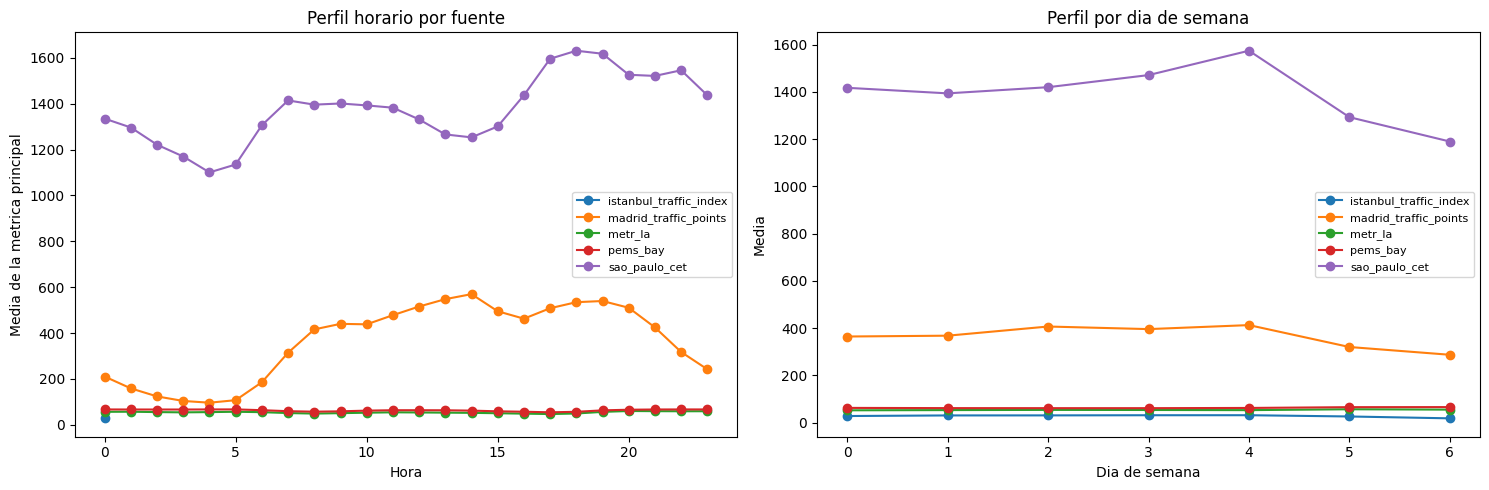

In [3]:
hourly_plot = hourly.groupby(['fuente', 'hora'], as_index=False)['media'].mean()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for source, group in hourly_plot.groupby('fuente'):
    axes[0].plot(group['hora'], group['media'], marker='o', linewidth=1.5, label=source)
axes[0].set_title('Perfil horario por fuente')
axes[0].set_xlabel('Hora')
axes[0].set_ylabel('Media de la metrica principal')
axes[0].legend(fontsize=8)
weekday_plot = weekday.groupby(['fuente', 'dia_semana'], as_index=False)['media'].mean()
for source, group in weekday_plot.groupby('fuente'):
    axes[1].plot(group['dia_semana'], group['media'], marker='o', linewidth=1.5, label=source)
axes[1].set_title('Perfil por dia de semana')
axes[1].set_xlabel('Dia de semana')
axes[1].set_ylabel('Media')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Lectura
Las coberturas no son equivalentes entre fuentes. Las comparaciones temporales deben respetar la ventana disponible de cada ciudad.